# Pipeline Project

You will be using the provided data to create a machine learning model pipeline.

You must handle the data appropriately in your pipeline to predict whether an
item is recommended by a customer based on their review.
Note the data includes numerical, categorical, and text data.

You should ensure you properly train and evaluate your model.

## The Data

The dataset has been anonymized and cleaned of missing values.

There are 8 features for to use to predict whether a customer recommends or does
not recommend a product.
The `Recommended IND` column gives whether a customer recommends the product
where `1` is recommended and a `0` is not recommended.
This is your model's target/

The features can be summarized as the following:

- **Clothing ID**: Integer Categorical variable that refers to the specific piece being reviewed.
- **Age**: Positive Integer variable of the reviewers age.
- **Title**: String variable for the title of the review.
- **Review Text**: String variable for the review body.
- **Positive Feedback Count**: Positive Integer documenting the number of other customers who found this review positive.
- **Division Name**: Categorical name of the product high level division.
- **Department Name**: Categorical name of the product department name.
- **Class Name**: Categorical name of the product class name.

The target:
- **Recommended IND**: Binary variable stating where the customer recommends the product where 1 is recommended, 0 is not recommended.

## Load Data

In [44]:
import pandas as pd

# Load data
df = pd.read_csv(
    'data/reviews.csv',
)

## Preparing features (`X`) & target (`y`)

In [45]:
data = df

# separate features from labels
X = data.drop('Recommended IND', axis=1)
y = data['Recommended IND'].copy()

print('Labels:', y.unique())
print('Features:')
display(X.head())

Labels: [0 1]
Features:


,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits


In [46]:
# Split data into train and test sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.1,
    shuffle=True,
    random_state=27,
)

# Your Work

## Data Exploration

In this section, I inspect the dataset's structure, dimensions, data types, and target variable distribution to understand what numerical, categorical, and text features I'm working with and identify any class imbalances in the target variable (`Recommended IND`).

In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18442 entries, 0 to 18441
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Clothing ID              18442 non-null  int64
 1   Age                      18442 non-null  int64
 2   Title                    18442 non-null  str  
 3   Review Text              18442 non-null  str  
 4   Positive Feedback Count  18442 non-null  int64
 5   Division Name            18442 non-null  str  
 6   Department Name          18442 non-null  str  
 7   Class Name               18442 non-null  str  
 8   Recommended IND          18442 non-null  int64
dtypes: int64(4), str(5)
memory usage: 1.3 MB


In [48]:
df.describe()

# The median age of the customers is 41 years. The minimum age is 18 years and the max. age is 99 years. 
# The standard deviation is 12 years, which means that most of the customers are between 30 and 54 years old.

# On average, there are more postive reviews than negative reviews. The mean of the 'Recommended IND' column is 0.82, 
# which means that 82% of the customers would recommend the clothing item to others. 
# The standard deviation is 0.38, which means that there is a significant variation in the reviews.

,Clothing ID,Age,Positive Feedback Count,Recommended IND
count,18442.000000,18442.000000,18442.000000,18442.000000
mean,954.896757,43.383635,2.697484,0.816235
std,141.571783,12.246264,5.942220,0.387303
min,2.000000,18.000000,0.000000,0.000000
25%,863.000000,34.000000,0.000000,1.000000
50%,952.000000,41.000000,1.000000,1.000000
75%,1078.000000,52.000000,3.000000,1.000000
max,1205.000000,99.000000,122.000000,1.000000


In [49]:
df['Recommended IND'].unique() #Categorical variable with 2 classes: 0 and 1

array([0, 1])

In [50]:
df['Division Name'].unique() 
df['Division Name'].value_counts() 

# There are two divisions in the dataset: 'General' and 'General Petite'.
# The 'General' division has 11,664 reviews, while the 'General Petite' division has 6778 reviews.

Division Name
General           11664
General Petite     6778
Name: count, dtype: int64

In [51]:
df['Department Name'].unique()
df['Department Name'].value_counts()

# There are 6 departments in the dataset: 'Bottoms' (3184), 'Dresses' (5371), 'Tops' (8713), 'Jackets' (879), 'Trend' (107), and 'Intimate' (188).

Department Name
Tops        8713
Dresses     5371
Bottoms     3184
Jackets      879
Intimate     188
Trend        107
Name: count, dtype: int64

In [52]:
df['Class Name'].unique()
df['Class Name'].value_counts()

# There are 14 classses in the dataset:

# - Class Name
# - Dresses           5371
# - Knits             3981
# - Blouses           2587
# - Sweaters          1218
# - Pants             1157
# - Jeans              970
# - Fine gauge         927
# - Skirts             796
# - Jackets            598
# - Outerwear          281
# - Shorts             260
# - Lounge             188
# - Trend              107
# - Casual bottoms       1

Class Name
Dresses           5371
Knits             3981
Blouses           2587
Sweaters          1218
Pants             1157
Jeans              970
Fine gauge         927
Skirts             796
Jackets            598
Outerwear          281
Shorts             260
Lounge             188
Trend              107
Casual bottoms       1
Name: count, dtype: int64

In [53]:
df.isnull().sum()

# The supplied dataset has no missing values. Imputation remains part of the
# pipeline so future reviews with missing features can still be processed.


Clothing ID                0
Age                        0
Title                      0
Review Text                0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
Recommended IND            0
dtype: int64

In [54]:
df.head()

,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name,Recommended IND
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses,0
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants,1
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses,1
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses,0
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits,1


In [55]:
df['Clothing ID'].unique().shape
df['Clothing ID'].duplicated().value_counts()

# Several reviews for the same clothing item. This is expected as multiple customers can review the same product.
# There are 531 unique clothing items in the dataset. The number of reviews is 18,442, which means that on average, each clothing item has 34.7 reviews.

Clothing ID
True     17911
False      531
Name: count, dtype: int64

## Building Pipeline

### Objective
To construct a modular machine learning pipeline using scikit-learn's `ColumnTransformer` and `Pipeline`. This ensures that numerical, categorical, and text features are preprocessed separately and correctly before feeding into the model.

In [56]:
# Define feature categories

numerical_features = ["Age", "Positive Feedback Count"]
categorical_features = ["Division Name", "Department Name", "Class Name", "Clothing ID"]
text_features = ["Review Text", "Title"]

In [57]:
# Numerical pipeline: normalize null markers (in case of new data), impute medians, then scale.

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer


def normalize_missing_values(df):
    return df.where(pd.notna(df), float('nan'))


numerical_pipeline = Pipeline(
    steps=[
        ('normalize_missing', FunctionTransformer(normalize_missing_values)),
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scaler', StandardScaler())
    ]
)


In [58]:
# Categorical pipeline

# 1. Fill missing values with the training-set mode.
# Clothing ID remains categorical even though its values are numeric.

from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(
    steps=[
        ('normalize_missing', FunctionTransformer(normalize_missing_values)),
        ('imputer', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)


In [59]:
# Text Processing Pipeline

# 1. Fill missing text before TF-IDF validates its input.
from functools import lru_cache
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer

nlp = spacy.load("en_core_web_sm")


def fill_missing_text(texts):
    return texts.fillna('').astype(str)


@lru_cache(maxsize=50000)

# 2. Define a custom tokenizer function that uses spaCy to tokenize the text, 
# remove stop words, punctuation, and whitespace, and return the lemmatized tokens in lowercase.


def custom_tokenizer(text):
    if pd.isna(text):
        return []
    doc = nlp(str(text))
    return [
        token.lemma_.lower() for token in doc
        if not token.is_stop and not token.is_punct and not token.is_space
    ]


text_pipeline = Pipeline(
    steps=[
        ('fill_missing', FunctionTransformer(fill_missing_text)),
        ('tfidf', TfidfVectorizer(
            tokenizer=custom_tokenizer, token_pattern=None, max_features=1000
        ))
    ]
)


### Building The Preprocessor with `ColumnTransformer`

Now, after creating all three separate pipelines, I will now aggregates these pipelines in a Column Transformer so that the necessary transformations apply to the correct columns.

In [60]:
from sklearn.compose import ColumnTransformer

preprocessing = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features),
        ('review_text', text_pipeline, 'Review Text'),
        ('title', text_pipeline, 'Title')
    ]
)

## Training Pipeline

### Objective
To combine our preprocessor `ColumnTransformer` and a classification model into a single end-to-end pipeline, split the dataset into training and testing sets, and train the model.

In [61]:
# Creating the final pipeline (preprocessing + model)

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessing),
        ('classifier', LogisticRegression(max_iter=100, random_state=42))
    ]
)

model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Clothing ID','Age','Title',...,'Division Name','Department Name', 'Class Name']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

## Fine-Tuning Pipeline

First, compare models using cross-validation on the training set, then evaluate the
best estimator once on the test set.


### Cross Validation

In [62]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(model_pipeline, X_train, y_train, cv=5, scoring='accuracy')

print(f"Cross-Validation Accuracy Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

Cross-Validation Accuracy Scores: [0.90090361 0.91054217 0.90238024 0.89484785 0.9047906 ]
Mean CV Accuracy: 0.9027 (+/- 0.0102)


### Hyperparameter Fine-tuning

In [63]:
from sklearn.model_selection import GridSearchCV

parameter_grid = {
    'classifier__C': [0.1, 1.0, 10.0],
}

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=parameter_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters Found:", grid_search.best_params_)
print(f"Best CV Accuracy: {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_

Fitting 5 folds for each of 3 candidates, totalling 15 fits


/Users/omolereasama/Desktop/Personal/data-science-projects/dsnd-pipelines-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/omolereasama/Desktop/Personal/data-science-projects/dsnd-pipelines-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the converge

Best Parameters Found: {'classifier__C': 1.0}
Best CV Accuracy: 0.9027


### Final Test Evaluation



Final Test Accuracy: 0.8493
Final Test Classification Report (precision, recall, F1-score):

              precision    recall  f1-score      support
0              0.769784  0.654434  0.707438   327.000000
1              0.927888  0.957839  0.942626  1518.000000
accuracy       0.904065  0.904065  0.904065     0.904065
macro avg      0.848836  0.806137  0.825032  1845.000000
weighted avg   0.899866  0.904065  0.900942  1845.000000


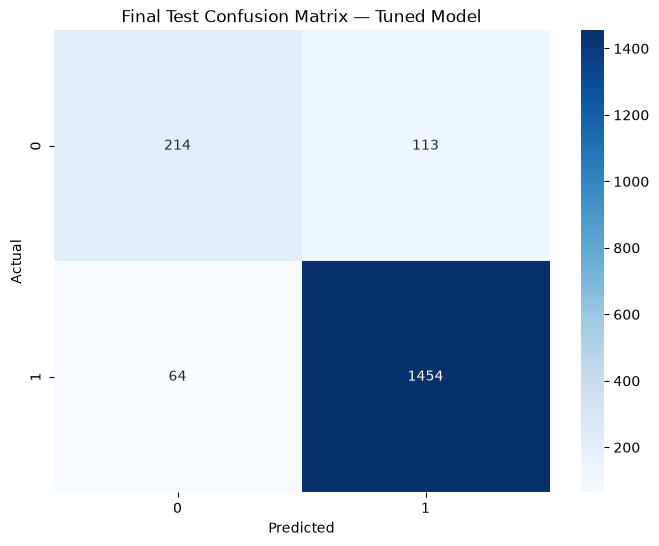

In [64]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = best_model.predict(X_test)
print(f"Final Test Accuracy: {pd.Series(y_pred).mean():.4f}")
print("Final Test Classification Report (precision, recall, F1-score):\n")
print(pd.DataFrame(classification_report(y_test, y_pred, digits=4, zero_division=0, output_dict=True)).T)

plt.figure(figsize=(8, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred, labels=[0, 1]),
    annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1], yticklabels=[0, 1]
)
plt.title("Final Test Confusion Matrix — Tuned Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


### Missing-value prediction check
Use synthetic reviews with missing numerical, categorical, and text values and an unseen category to verify prediction robustness without reusing the test set.


In [65]:
import numpy as np

# Exercise NaN, None, and pandas.NA in each feature group, plus an all-null row.
missing_reviews = X_train.iloc[:4].copy().astype(object)
for row, marker in enumerate([np.nan, None, pd.NA]):
    missing_reviews.iloc[row, :] = marker
missing_reviews.iloc[3, :] = np.nan
missing_reviews.iloc[0, missing_reviews.columns.get_loc('Division Name')] = 'Unseen division'

missing_predictions = best_model.predict(missing_reviews)
assert missing_predictions.shape == (len(missing_reviews),)
assert set(missing_predictions).issubset({0, 1})
print("Predictions for reviews with missing features:", missing_predictions)


Predictions for reviews with missing features: [1 1 1 1]
